In [2]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from zpyhelper.filesys import checkdir
import json
from zpyhelper.MVPA.rdm import compute_rdm, lower_tri
import seaborn as sns
from joblib import load, Parallel, delayed
project_path = r'E:\pirate_fmri\Analysis'
sys.path.append(project_path)

import matplotlib as mpl
font_paths = mpl.font_manager.findSystemFonts()
mpl.font_manager.get_font_names()
sns.set_style('white',rc = dict(font='Arial'))  # set font globally for seaborn


In [3]:
import warnings
warnings.simplefilter('ignore', category=FutureWarning)

# Load data
study_scripts = os.path.join(project_path,'scripts','Exp1_fmri')
with open(os.path.join(study_scripts,'pirate_defaults.json')) as f:
    pirate_defaults = json.load(f)
    subid_list = pirate_defaults['participants']['validids']
    nongeneralizers = pirate_defaults['participants']["nongeneralizerids"]
    generalizers    = pirate_defaults['participants']["generalizerids"]
print(f"N_participants = {len(subid_list)}")

N_participants = 56


In [4]:
pretrained_weights_dir = os.path.join(project_path,"scripts","Exp1_fmri","deepmreye","pretrained_model_weights_FreyNau")
pretrained_models  = dict(zip(
    ['m1_guidedfixations','m2_pursuit','m3_pursuit','m4_pursuit',
     'm5_freeviewing','m6_openclosed','m7_multiDS1to5','m8_multiDS1to6'],
    ['dataset1_guided_fixations.h5',
     'dataset2_pursuit.h5',
     'dataset3_pursuit.h5',
     'dataset4_pursuit.h5',
     'dataset5_free_viewing.h5',
     'dataset6_openclosed.h5',
     'datasets_1to5.h5',
     'datasets_1to6.h5']
))
raw_img_type = "onlyrealigned"
decoding_res_dir = f"e:/pirate_fmri/Analysis/data/Exp1_fmri/fmri/deepmreye/results/{raw_img_type}/"
processed_data_dir = f"e:/pirate_fmri/Analysis/data/Exp1_fmri/fmri/deepmreye/processed/{raw_img_type}/"
ROIRSAdir =  os.path.join(project_path,"data","Exp1_fmri", "fmri", "ROIdata")


In [5]:
# Load effective voxel count files 
mean_effvox_count_df = pd.read_csv(os.path.join(decoding_res_dir,'mean_effective_voxel_count_per_task.csv'))

# check consistency between models

In [6]:
itvalue = 10 # innerTS only has one value: 10 (because we are only using pretrained models here)
model_predictions = {}
for mname, pretrained_weights_fn in pretrained_models.items():
    model_predictions[mname] = load(os.path.join(decoding_res_dir,mname,'DM_predictions.pkl'))
    

In [7]:
itvalue = 10 # innerTS only has one value: 10 (because we are only using pretrained models here)
# for each participants, get the model predictions from each model
model_consistencies = {}
for taskname in ["piratenavigation","localizer"]:
    run_list = [1] if taskname=="localizer" else [1,2,3,4]
    model_consistencies[taskname] = []
    for run in run_list:
        print(f"Computing consistencies for task {taskname}, run {run}")
        tmp_consistencies = []
        for subid in subid_list:
            sub_predictions = {}
            for mname in pretrained_models.keys():
                pred_y = model_predictions[mname][itvalue][taskname][subid][run_list.index(run)] # each is of shape (n_TR, itvalue, 2)
                # reshape to (n_TR,) by taking the median across the all inner TR timepoints 
                pred_y_median = np.median(pred_y, axis=1) # shape (n_TR, 2)
                pred_y_tan = np.tan(np.deg2rad(pred_y_median))
                sub_predictions[mname] = pred_y_tan
            # compute consistency between models for x and y separately
            consistency_matrices = [
                1-compute_rdm(np.vstack([v[:,0] for m,v in sub_predictions.items()]), metric='correlation'), # X
                1-compute_rdm(np.vstack([v[:,1] for m,v in sub_predictions.items()]), metric='correlation')  # Y
            ]
            tmp_consistencies.append(consistency_matrices)
        model_consistencies[taskname].append(tmp_consistencies)

Computing consistencies for task piratenavigation, run 1
Computing consistencies for task piratenavigation, run 2
Computing consistencies for task piratenavigation, run 3


Computing consistencies for task piratenavigation, run 4
Computing consistencies for task localizer, run 1


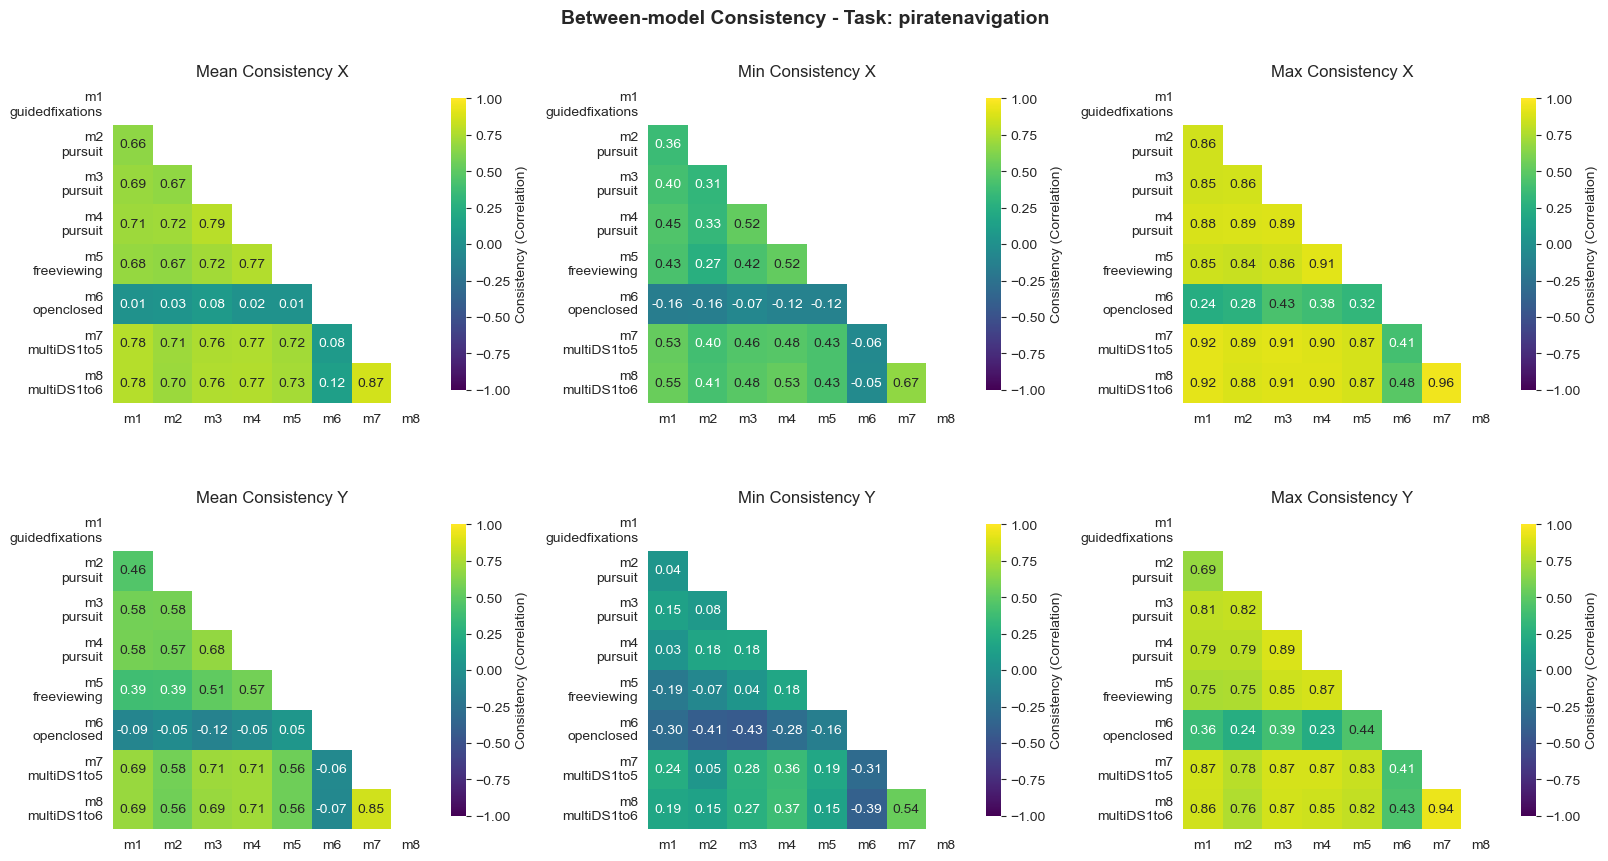

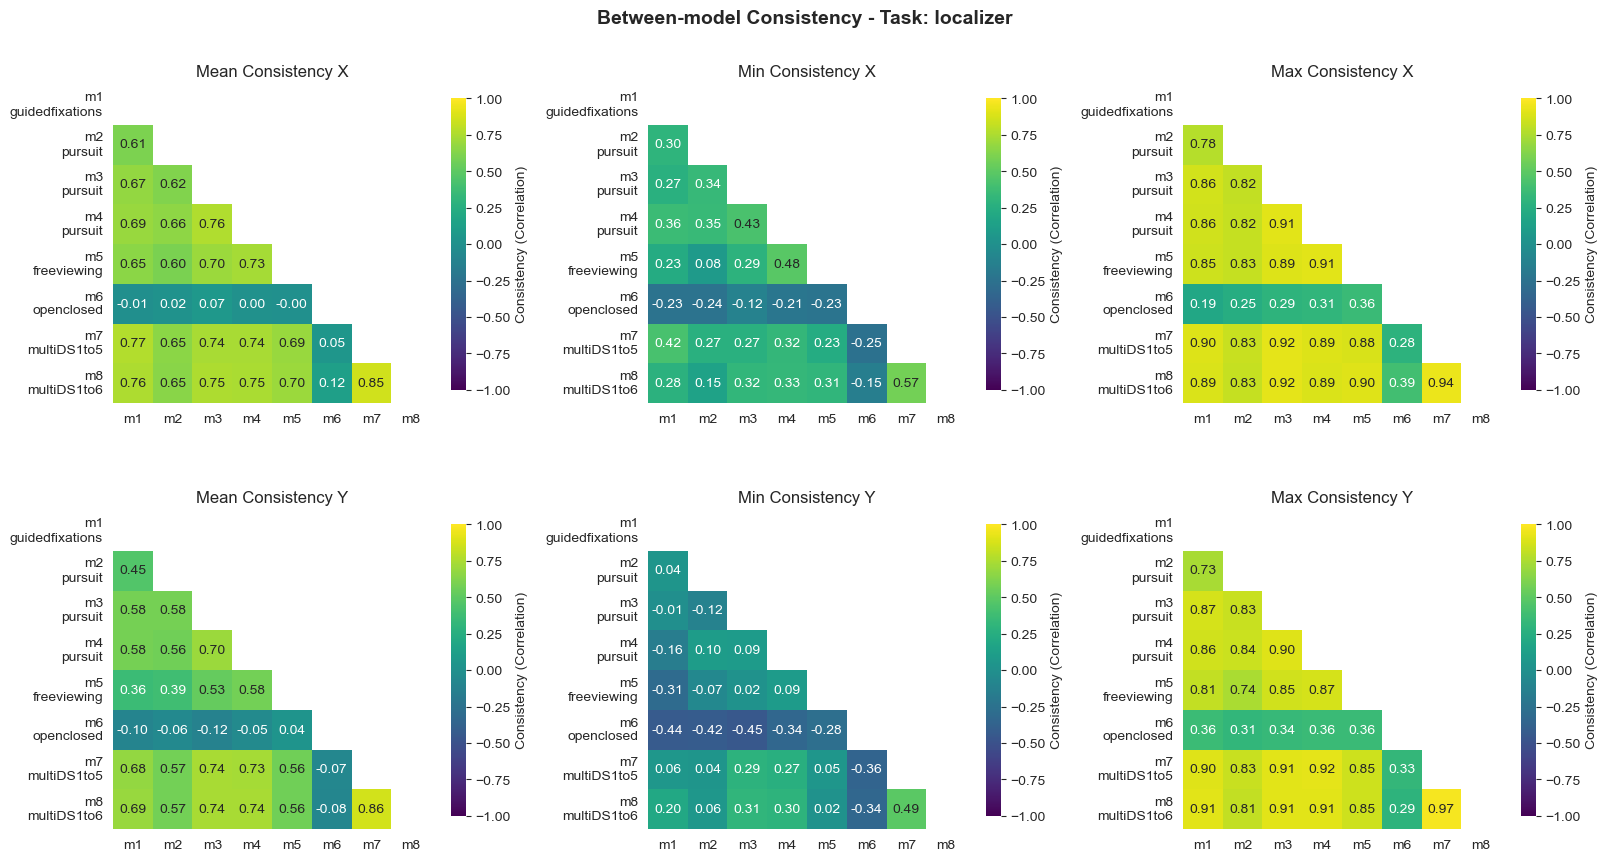

In [8]:
for taskname in model_consistencies.keys():
    # model_consistencies[taskname] is of shape (n_runs, n_subs, 2, n_models, n_models)
    mean_across_runs = np.mean(model_consistencies[taskname], axis=0) # shape (n_subs, 2, n_models, n_models)
    # then we compute the min, max, and mean across subjects for x and y separately
    mean_consistency_x = np.mean(mean_across_runs[:,0,:,:], axis=0)
    mean_consistency_y = np.mean(mean_across_runs[:,1,:,:], axis=0)
    min_consistency_x = np.min(mean_across_runs[:,0,:,:], axis=0)
    min_consistency_y = np.min(mean_across_runs[:,1,:,:], axis=0)
    max_consistency_x = np.max(mean_across_runs[:,0,:,:], axis=0)
    max_consistency_y = np.max(mean_across_runs[:,1,:,:], axis=0)
    
    plt_mats = dict(zip(
        ["Mean Consistency X", "Min Consistency X", "Max Consistency X",
         "Mean Consistency Y", "Min Consistency Y", "Max Consistency Y"],
        [mean_consistency_x, min_consistency_x, max_consistency_x,
         mean_consistency_y, min_consistency_y, max_consistency_y]
    ))  
    # only keep the lower triangle (set upper triangle to nan)
    for k,mat in plt_mats.items():
        nan_mat = np.full(mat.shape, np.nan)
        nan_mat[lower_tri(mat)[1]] = lower_tri(mat)[0]
        plt_mats[k] = nan_mat
    model_names = list(pretrained_models.keys())
    model_name_print = [x.replace("_","\n") for x in model_names]

    # plot heatmaps for x and y, min, max, mean
    fig, axes = plt.subplots(2,3, figsize=(9*1.8,5*1.8))
    for i, (title, mat) in enumerate(plt_mats.items()):
        ax = axes.flatten()[i]
        sns.heatmap(mat, yticklabels=model_name_print, xticklabels=[x[:2] for x in model_name_print], 
                    ax=ax, vmin=-1, vmax=1, cmap='viridis', annot=True, fmt=".2f",square=True,
                    cbar_kws={"shrink": .75, 'label': 'Consistency (Correlation)'})
        # set the angle of x-tick labels
        ax.tick_params(axis='x', rotation=0)
        ax.set_title(f"{title}")
    fig.suptitle(f"Between-model Consistency - Task: {taskname}", fontsize=14,fontweight='bold')
    plt.tight_layout()
    plt.show()

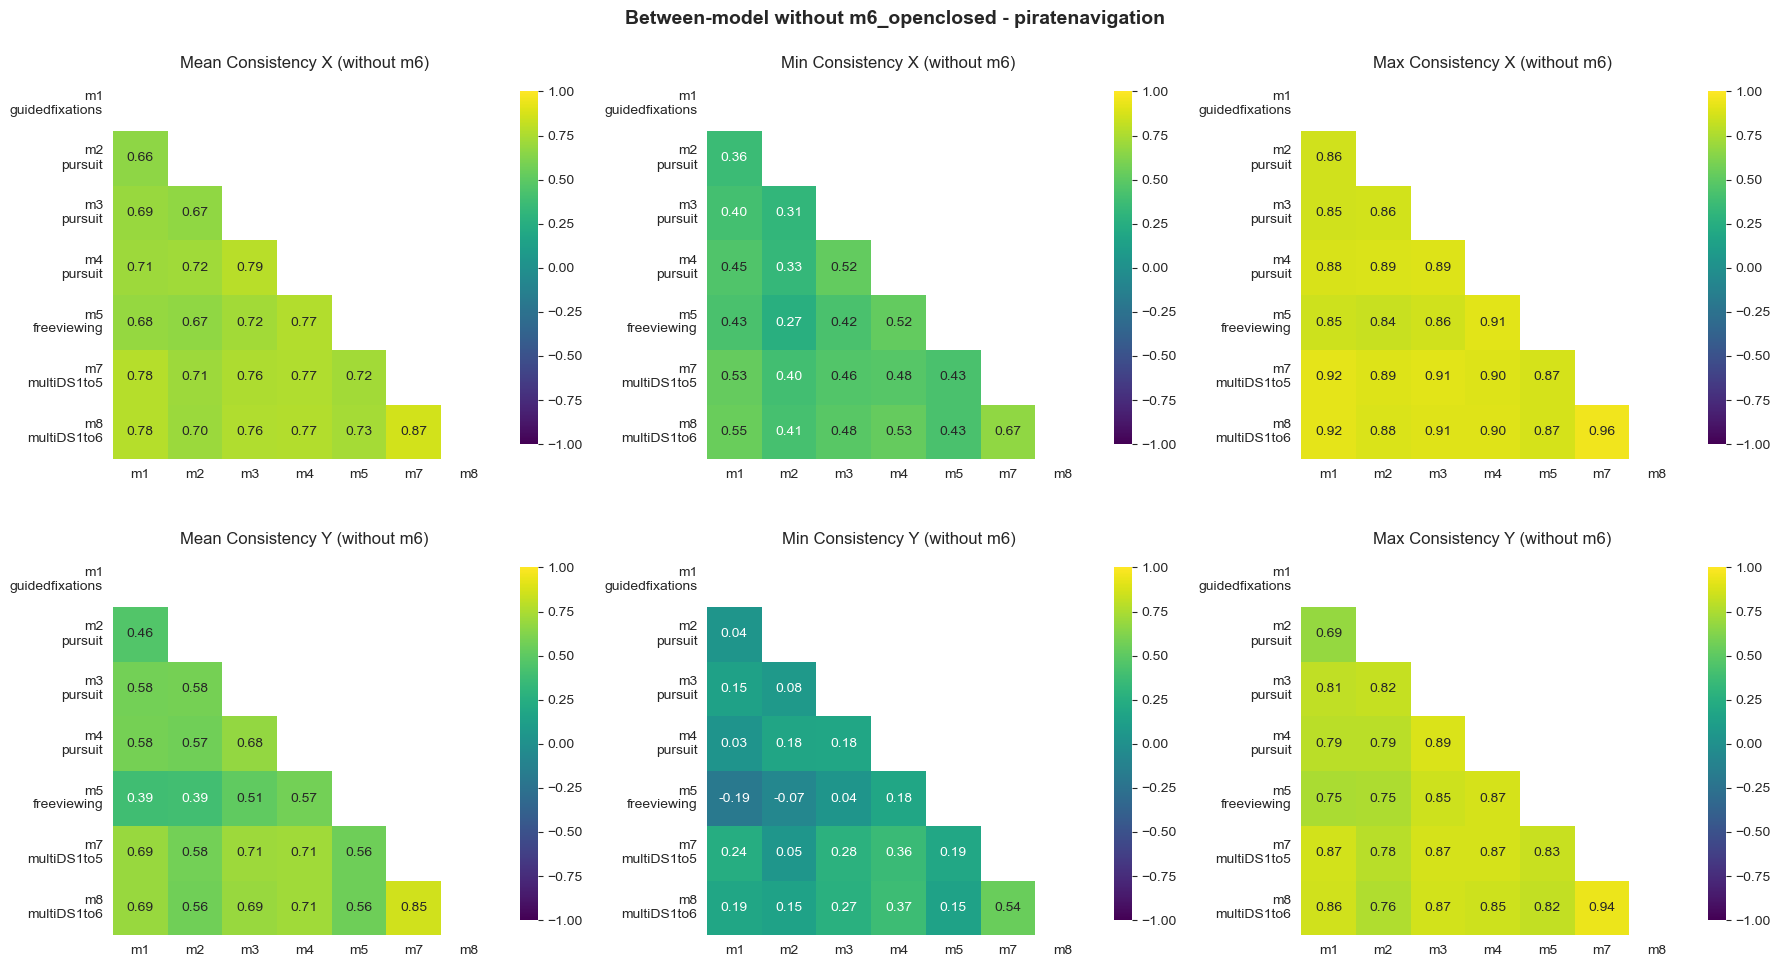

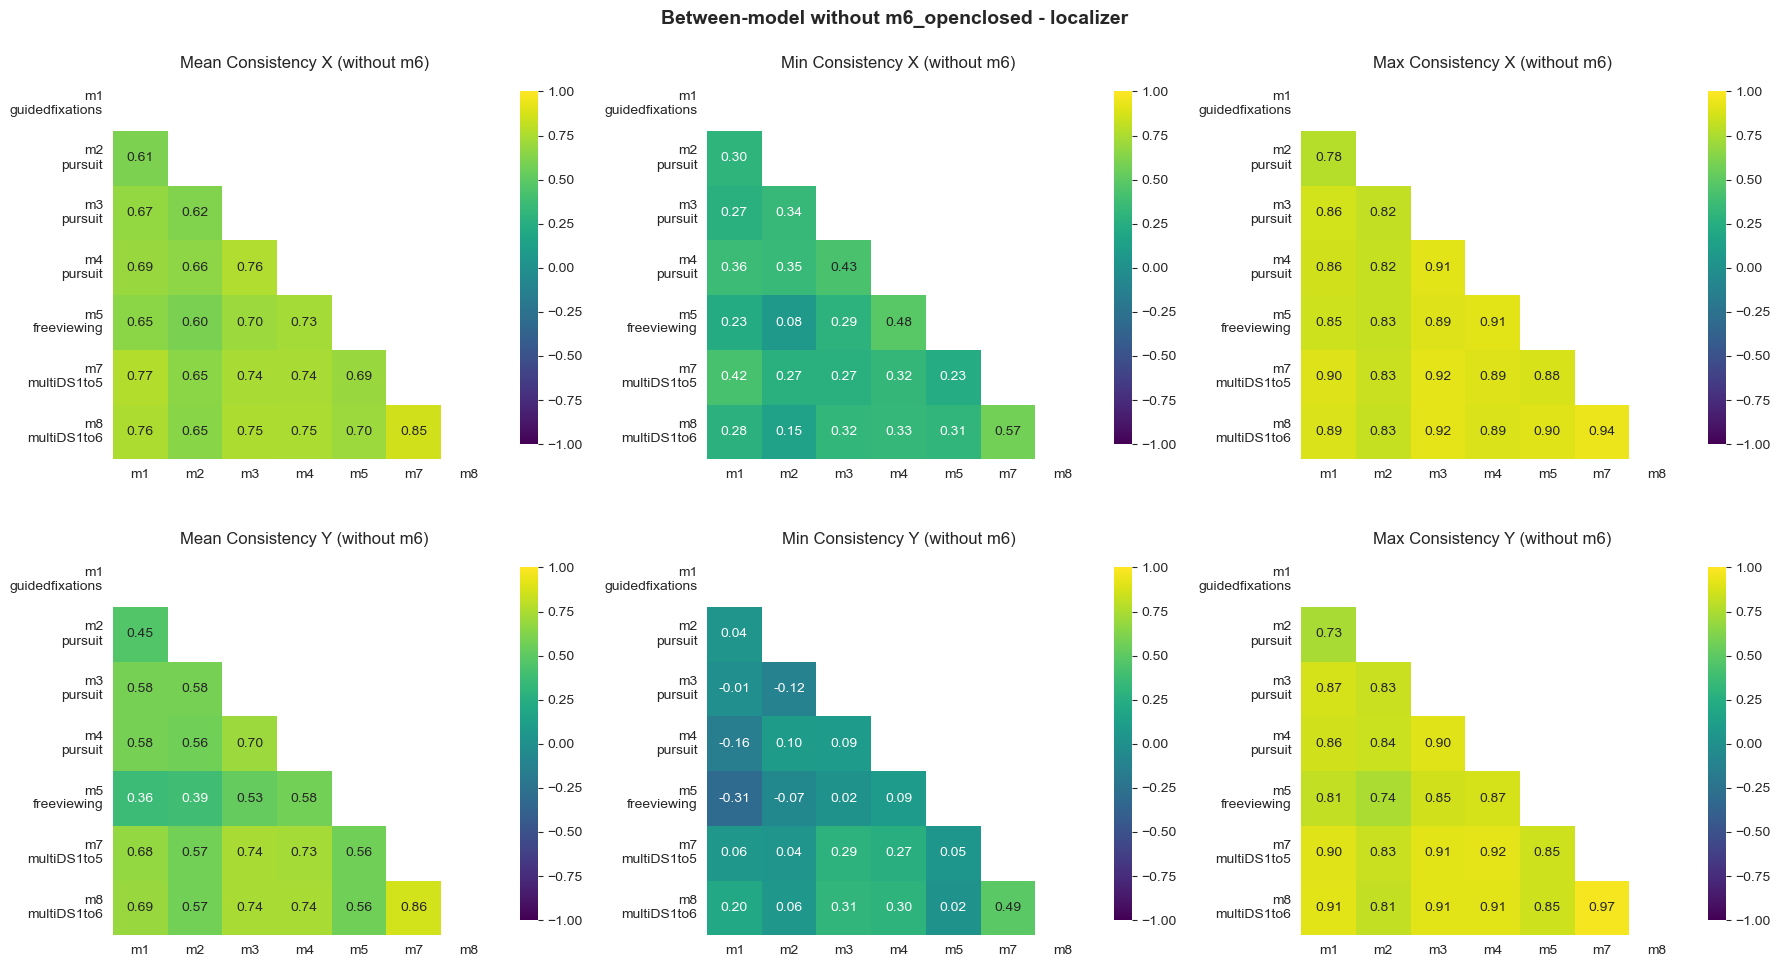

In [9]:
# m6_openclosed deviated a lot from the other models, so we also plot the consistency matrices without m6_openclosed
for taskname in model_consistencies.keys():
    # model_consistencies[taskname] is of shape (n_runs, n_subs, 2, n_models, n_models)
    mean_across_runs = np.mean(model_consistencies[taskname], axis=0) # shape (n_subs, 2, n_models, n_models)
    # then we compute the min, max, and mean across subjects for x and y separately
    mean_consistency_x = np.mean(mean_across_runs[:,0,:,:], axis=0)
    mean_consistency_y = np.mean(mean_across_runs[:,1,:,:], axis=0)
    min_consistency_x = np.min(mean_across_runs[:,0,:,:], axis=0)
    min_consistency_y = np.min(mean_across_runs[:,1,:,:], axis=0)
    max_consistency_x = np.max(mean_across_runs[:,0,:,:], axis=0)
    max_consistency_y = np.max(mean_across_runs[:,1,:,:], axis=0)
    
    
    # remove m6_openclosed (index 5)
    model_names = list(pretrained_models.keys())
    removemodels = ['m6_openclosed']
    indices_to_keep = [i for i,m in enumerate(pretrained_models) if m not in removemodels]
    mean_consistency_x = mean_consistency_x[np.ix_(indices_to_keep, indices_to_keep)]
    mean_consistency_y = mean_consistency_y[np.ix_(indices_to_keep, indices_to_keep)]
    min_consistency_x = min_consistency_x[np.ix_(indices_to_keep, indices_to_keep)]
    min_consistency_y = min_consistency_y[np.ix_(indices_to_keep, indices_to_keep)]
    max_consistency_x = max_consistency_x[np.ix_(indices_to_keep, indices_to_keep)]
    max_consistency_y = max_consistency_y[np.ix_(indices_to_keep, indices_to_keep)]
    model_names_filtered = np.array(model_names)[indices_to_keep]
    model_names_filtered_print = [x.replace("_","\n") for x in model_names_filtered]
    
    # only keep the lower triangle (set upper triangle to nan)
    plt_mats = dict(zip(
        ["Mean Consistency X", "Min Consistency X", "Max Consistency X",
         "Mean Consistency Y", "Min Consistency Y", "Max Consistency Y"],
        [mean_consistency_x, min_consistency_x, max_consistency_x,
         mean_consistency_y, min_consistency_y, max_consistency_y]
    ))  
    for k,mat in plt_mats.items():
        nan_mat = np.full(mat.shape, np.nan)
        nan_mat[lower_tri(mat)[1]] = lower_tri(mat)[0]
        plt_mats[k] = nan_mat

    # plot heatmaps for x and y, min, max, mean with %.2f showing values     
    fig, axes = plt.subplots(2,3, figsize=(18,10))
    for i, (title, mat) in enumerate(plt_mats.items()):
        ax = axes.flatten()[i]
        sns.heatmap(mat, 
                    xticklabels=[x[:2] for x in model_names_filtered_print], yticklabels=model_names_filtered_print, 
                    ax=ax, vmin=-1, vmax=1, cmap='viridis', annot=True, fmt=".2f", square=True,cbar_kws={"shrink": .8})
        ax.set_title(f"{title} (without m6)")

    fig.suptitle(f"Between-model without m6_openclosed - {taskname}", fontsize=14,fontweight='bold')
    plt.tight_layout()

In [10]:
# plot each model's mean consistency with other models, for x and y separately, except m6_openclosed
model_consistency_dfs = []
for taskname in model_consistencies.keys():
    mean_across_runs = np.mean(model_consistencies[taskname], axis=0) # shape (n_subs, 2, n_models, n_models)
    mean_consistency_x = mean_across_runs[:,0,:,:]
    mean_consistency_y = mean_across_runs[:,1,:,:]
    # remove m6_openclosed (index 5)
    model_names = list(pretrained_models.keys())
    removemodels = ['m6_openclosed']
    indices_to_keep = [i for i,m in enumerate(pretrained_models) if m not in removemodels]
    mean_consistency_x = np.array([x[np.ix_(indices_to_keep, indices_to_keep)] for x in mean_consistency_x])
    mean_consistency_y = np.array([y[np.ix_(indices_to_keep, indices_to_keep)] for y in mean_consistency_y])
    model_names_filtered = np.array(model_names)[indices_to_keep]
    # compute each model's mean consistency with other models for each participant
    mean_model_consistencies = {
        'x': {mname: np.mean(mean_consistency_x[:,i, np.arange(len(model_names_filtered)) != i], axis=1) 
              for i, mname in enumerate(model_names_filtered)},
        'y': {mname: np.mean(mean_consistency_y[:,i, np.arange(len(model_names_filtered)) != i], axis=1)  
              for i, mname in enumerate(model_names_filtered)}
    }
    tmpdf = pd.DataFrame({
            "consistency_x": np.concatenate([mean_model_consistencies["x"][m] for m in model_names_filtered]),
            "consistency_y": np.concatenate([mean_model_consistencies["y"][m] for m in model_names_filtered]),
            "pretrainedmodel": np.concatenate([[m]*len(subid_list) for m in model_names_filtered]),
            "subid": np.concatenate([subid_list]*len(model_names_filtered))
            }).assign(taskname=taskname)
    model_consistency_dfs.append(tmpdf)

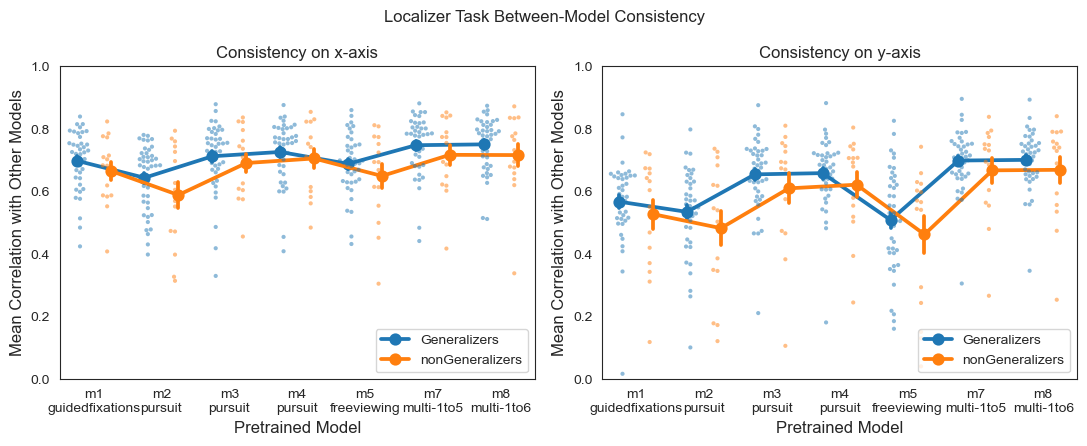

In [11]:
model_consistency_df = pd.concat(model_consistency_dfs, axis=0).reset_index(drop=True)
model_consistency_df["subgroup"] = ["Generalizers" if subid in generalizers else "nonGeneralizers" for subid in model_consistency_df["subid"]]
model_consistency_df["pretrainedmodel_print"] = model_consistency_df["pretrainedmodel"].str.replace("_","\n").str.replace("DS","-")
# plot the consistencies for x and y separately and for each task for each subgroup
# x:model, y:consistency (x or y), row: task, colours: subgroup
fig,axes = plt.subplots(1,2, figsize=(11,4.5),squeeze=False)
for j,consistency_type in enumerate(['consistency_x','consistency_y']):
    for i, taskname in enumerate(list(model_consistencies.keys())[-1:]):
        ax = axes[i,j]
        axdf = model_consistency_df[model_consistency_df["taskname"]==taskname].copy()
        sns.pointplot(data=axdf, x='pretrainedmodel_print', y=consistency_type, hue='subgroup',
                    dodge=0.5, errorbar='se', ax=ax)
        sns.swarmplot(data=axdf, x='pretrainedmodel_print', y=consistency_type, hue='subgroup',
                    dodge=True, alpha=0.5, ax=ax,size=3)
        ax_title = f"Consistency on {consistency_type[-1]}-axis"
        ax.set_title(ax_title)
        ax.set_xlabel("Pretrained Model", fontsize=12)
        ax.set_ylabel("Mean Correlation with Other Models", fontsize=12)
        # only plot the first two legends for pointplot
        lgends = ax.get_legend_handles_labels()
        ax.legend_.remove()
        ax.legend(handles=lgends[0][:2], labels=lgends[1][:2], title='', loc='lower right')
        ax.set_ylim([0,1.0])
plot_title = f"{taskname} task between-model consistency"
plt.suptitle(plot_title.title())
#for ax in axes.flatten():
#    ax.legend_.remove()
plt.tight_layout()


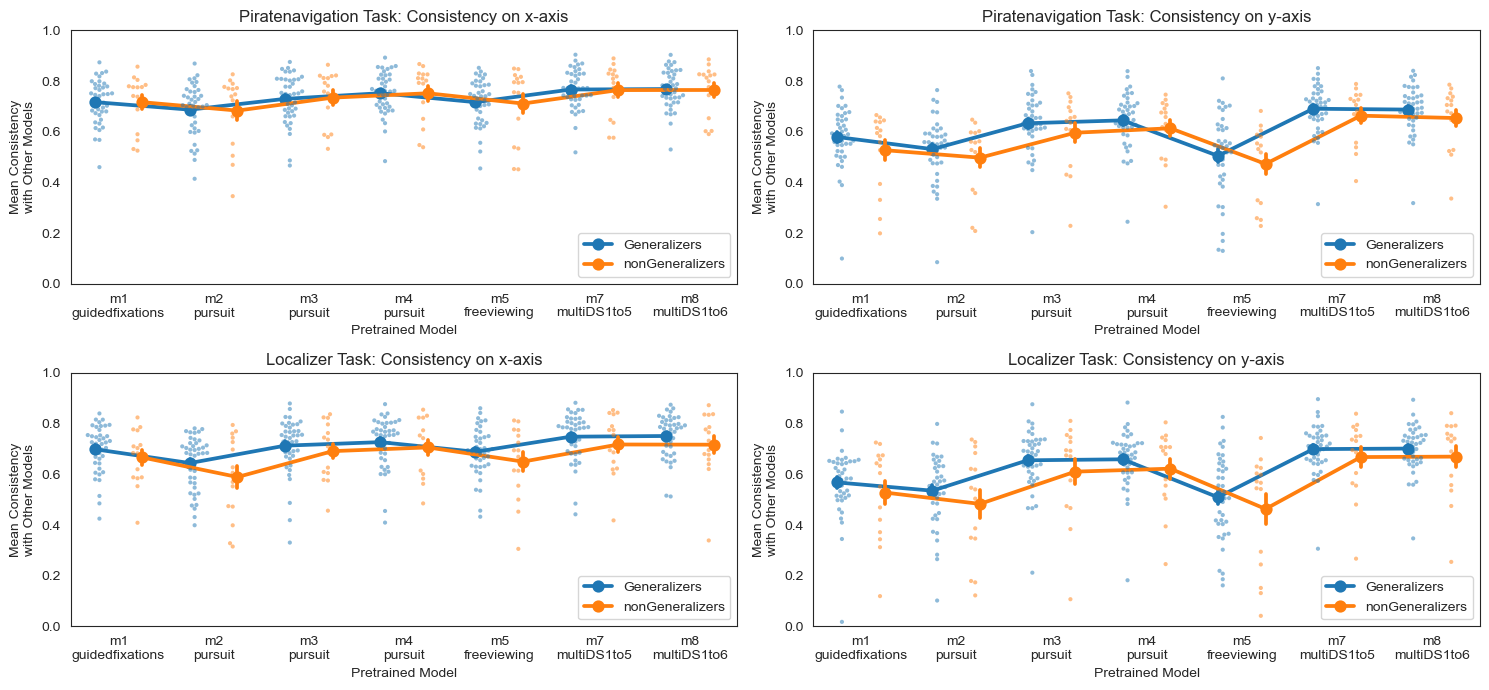

In [12]:
model_consistency_df = pd.concat(model_consistency_dfs, axis=0).reset_index(drop=True)
model_consistency_df["subgroup"] = ["Generalizers" if subid in generalizers else "nonGeneralizers" for subid in model_consistency_df["subid"]]
model_consistency_df["pretrainedmodel_print"] = model_consistency_df["pretrainedmodel"].str.replace("_","\n")
# plot the consistencies for x and y separately and for each task for each subgroup
# x:model, y:consistency (x or y), row: task, colours: subgroup
fig,axes = plt.subplots(2,2, figsize=(15,7))
for j,consistency_type in enumerate(['consistency_x','consistency_y']):
    for i, taskname in enumerate(model_consistencies.keys()):
        ax = axes[i,j]
        axdf = model_consistency_df[model_consistency_df["taskname"]==taskname].copy()
        sns.pointplot(data=axdf, x='pretrainedmodel_print', y=consistency_type, hue='subgroup',
                    dodge=0.5, errorbar='se', ax=ax)
        sns.swarmplot(data=axdf, x='pretrainedmodel_print', y=consistency_type, hue='subgroup',
                    dodge=True, alpha=0.5, ax=ax,size=3)
        ax.tick_params(axis='x', rotation=0)
        ax.set_title(f"{taskname.title()} Task: Consistency on {consistency_type[-1]}-axis")
        ax.set_xlabel("Pretrained Model")
        ax.set_ylabel("Mean Consistency\nwith Other Models")
        # only plot the first two legends for pointplot
        lgends = ax.get_legend_handles_labels()
        ax.legend_.remove()
        ax.legend(handles=lgends[0][:2], labels=lgends[1][:2], title='', loc='lower right')
        ax.set_ylim([0,1.0])

#for ax in axes.flatten():
#    ax.legend_.remove()
plt.tight_layout()


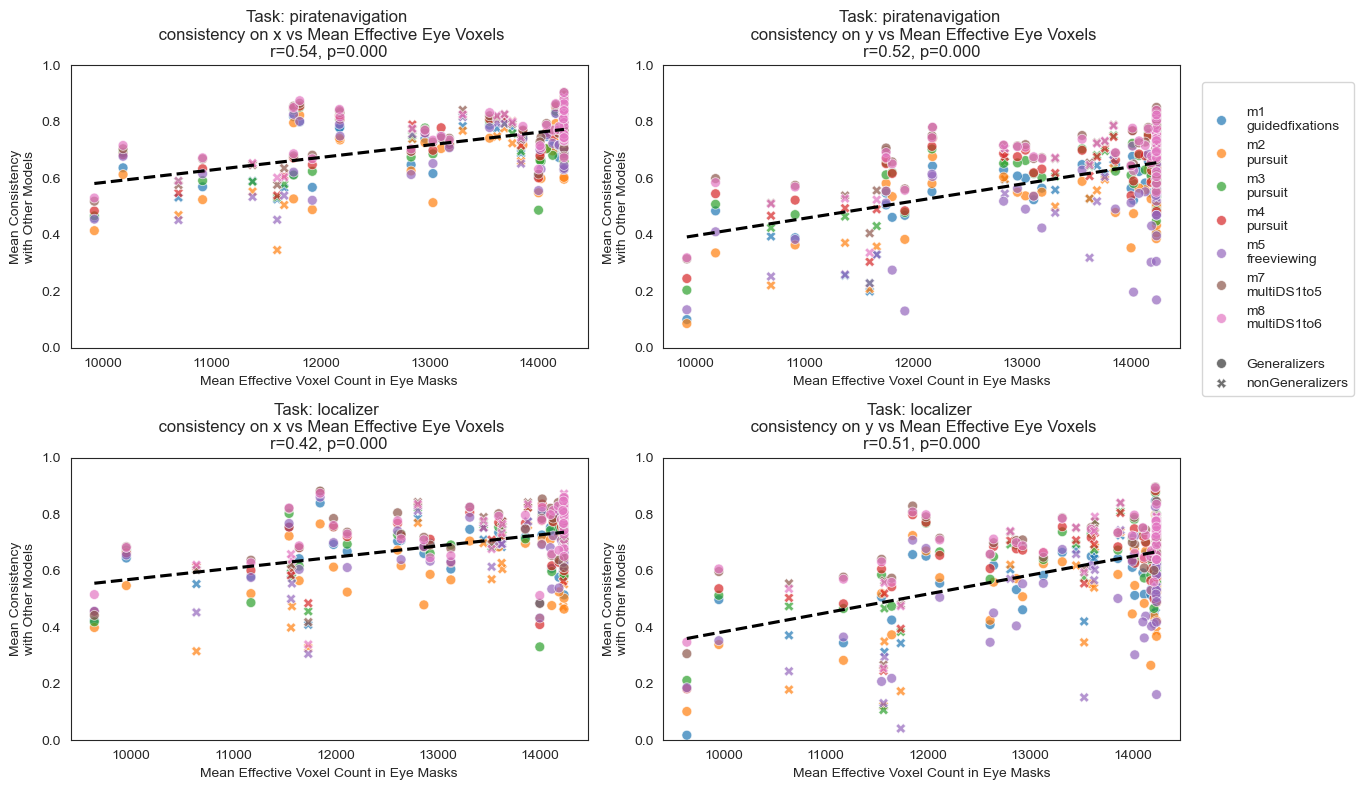

In [13]:
## consistency as a function of number of voxels in eye masks

corr_effvox_consistency_df = model_consistency_df.merge(
    mean_effvox_count_df, on=['subid','taskname'], how='left'
)
corr_effvox_consistency_df

# plot consistency vs mean effective voxel count for each pretrained model, for x and y separately
fig, axes = plt.subplots(2,2, figsize=(12,8))
for j,consistency_type in enumerate(['consistency_x','consistency_y']):
    for i, taskname in enumerate(model_consistencies.keys()):
        ax = axes[i,j]
        axdf = corr_effvox_consistency_df[corr_effvox_consistency_df["taskname"]==taskname].copy()
        sns.scatterplot(data=axdf, x='mean_effvox_count', y=consistency_type, hue='pretrainedmodel_print', style='subgroup', s=50, ax=ax, alpha=0.7)
        sns.regplot(data=axdf, x='mean_effvox_count', y=consistency_type, scatter=False, ax=ax, ci=None, color='black', line_kws={'linestyle':'--'})
        # compute Pearson correlation
        from scipy.stats import pearsonr
        r, p = pearsonr(axdf['mean_effvox_count'], axdf[consistency_type])
        ax.set_title(f"Task: {taskname} \n {consistency_type.replace('_',' on ')} vs Mean Effective Eye Voxels\nr={r:.2f}, p={p:.3f}")
        ax.set_xlabel("Mean Effective Voxel Count in Eye Masks")
        ax.set_ylabel("Mean Consistency\nwith Other Models")
        
        #ax.legend(title='Pretrained Model', loc='lower right')
        ax.set_ylim([0,1.0])
lgends = ax.get_legend_handles_labels()
fig.legend(handles=lgends[0], labels=[x if i not in [0,8] else '' for i,x in enumerate(lgends[1])], 
           loc='upper left', bbox_to_anchor=(1,0.9))
for ax in axes.flatten():
    ax.legend_.remove()

plt.tight_layout()

# check consistency with behaviour

In [14]:
# load the timecourse of experiment to see if the gaze predictions make sense

lzercorr_dir = os.path.join(decoding_res_dir,'localizer_lag_correlation')
lag_correlation_df = pd.read_csv(os.path.join(lzercorr_dir,'lag_correlations_allsubs.csv'))
lag_correlation_df["subgroup"] = lag_correlation_df["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
lag_correlation_df["pretrainedmodel_print"] = lag_correlation_df["pretrainedmodel"].str.replace("_","\n").str.replace("DS","-")

In [15]:
# show a summary of lag correlations for each model at the lag of 1 TR
# compute a mean correlation of x and y column
lag_correlation_df['correlation_xymean'] = lag_correlation_df[['correlation_x', 'correlation_y']].mean(axis=1)
# show mean and s.e.m for each model at lag 1 TR
lag_correlation_df[lag_correlation_df["lag_TR"]==1].groupby("pretrainedmodel_print")[["correlation_xymean", "correlation_x", "correlation_x"]].agg(['mean','sem'])


correlation_xymean           correlation_x            \
                                    mean       sem          mean       sem   
pretrainedmodel_print                                                        
m1\nguidedfixations             0.424610  0.014021      0.535476  0.015482   
m2\npursuit                     0.451646  0.017348      0.504146  0.017039   
m3\npursuit                     0.535086  0.014704      0.600334  0.014269   
m4\npursuit                     0.482350  0.014897      0.559447  0.015549   
m5\nfreeviewing                 0.437998  0.014172      0.523474  0.015603   
m7\nmulti-1to5                  0.546174  0.014868      0.596970  0.015167   
m8\nmulti-1to6                  0.533909  0.015034      0.588340  0.015648   

                                           
                           mean       sem  
pretrainedmodel_print                      
m1\nguidedfixations    0.535476  0.015482  
m2\npursuit            0.504146  0.017039  
m3\npursuit            0.600334  0.014269  
m4\npursuit            0.559447  0.015549  
m5\nfreeviewing        0.523474  0.015603  
m7\nmulti-1to5         0.596970  0.015167  
m8\nmulti-1to6         0.588340  0.015648

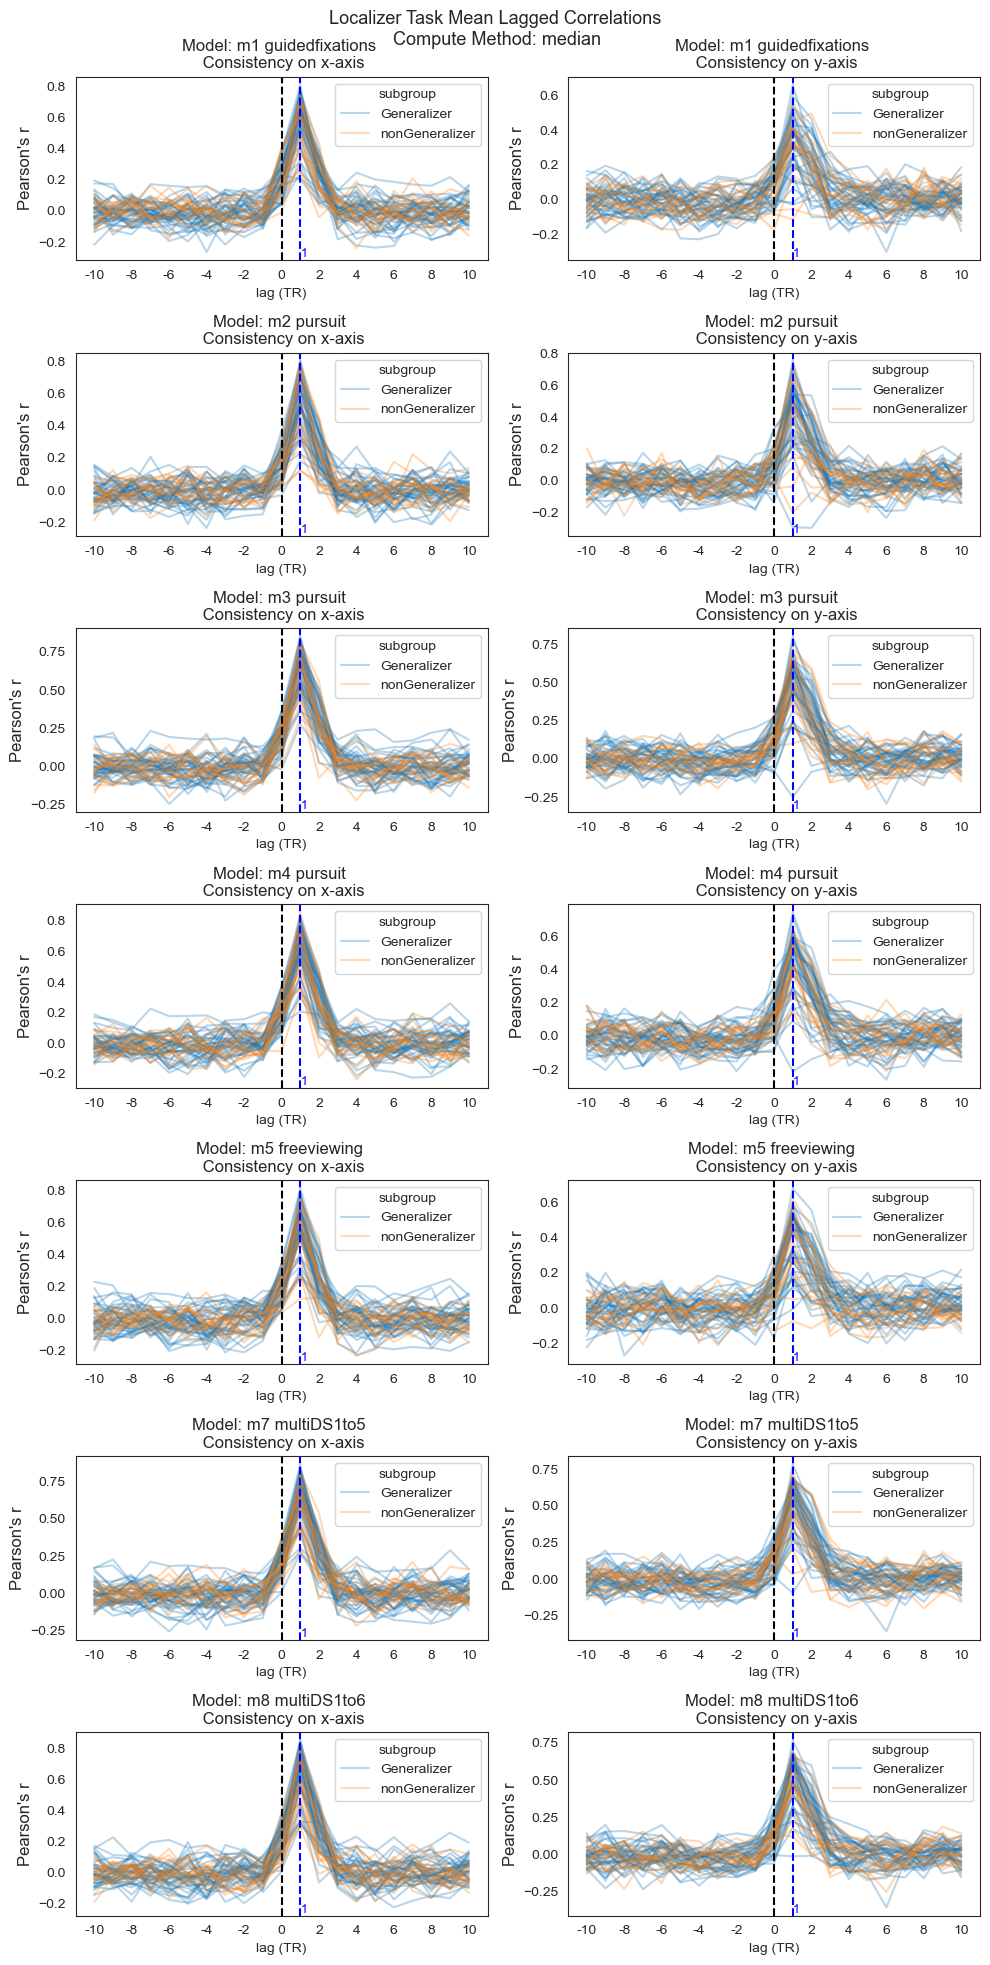

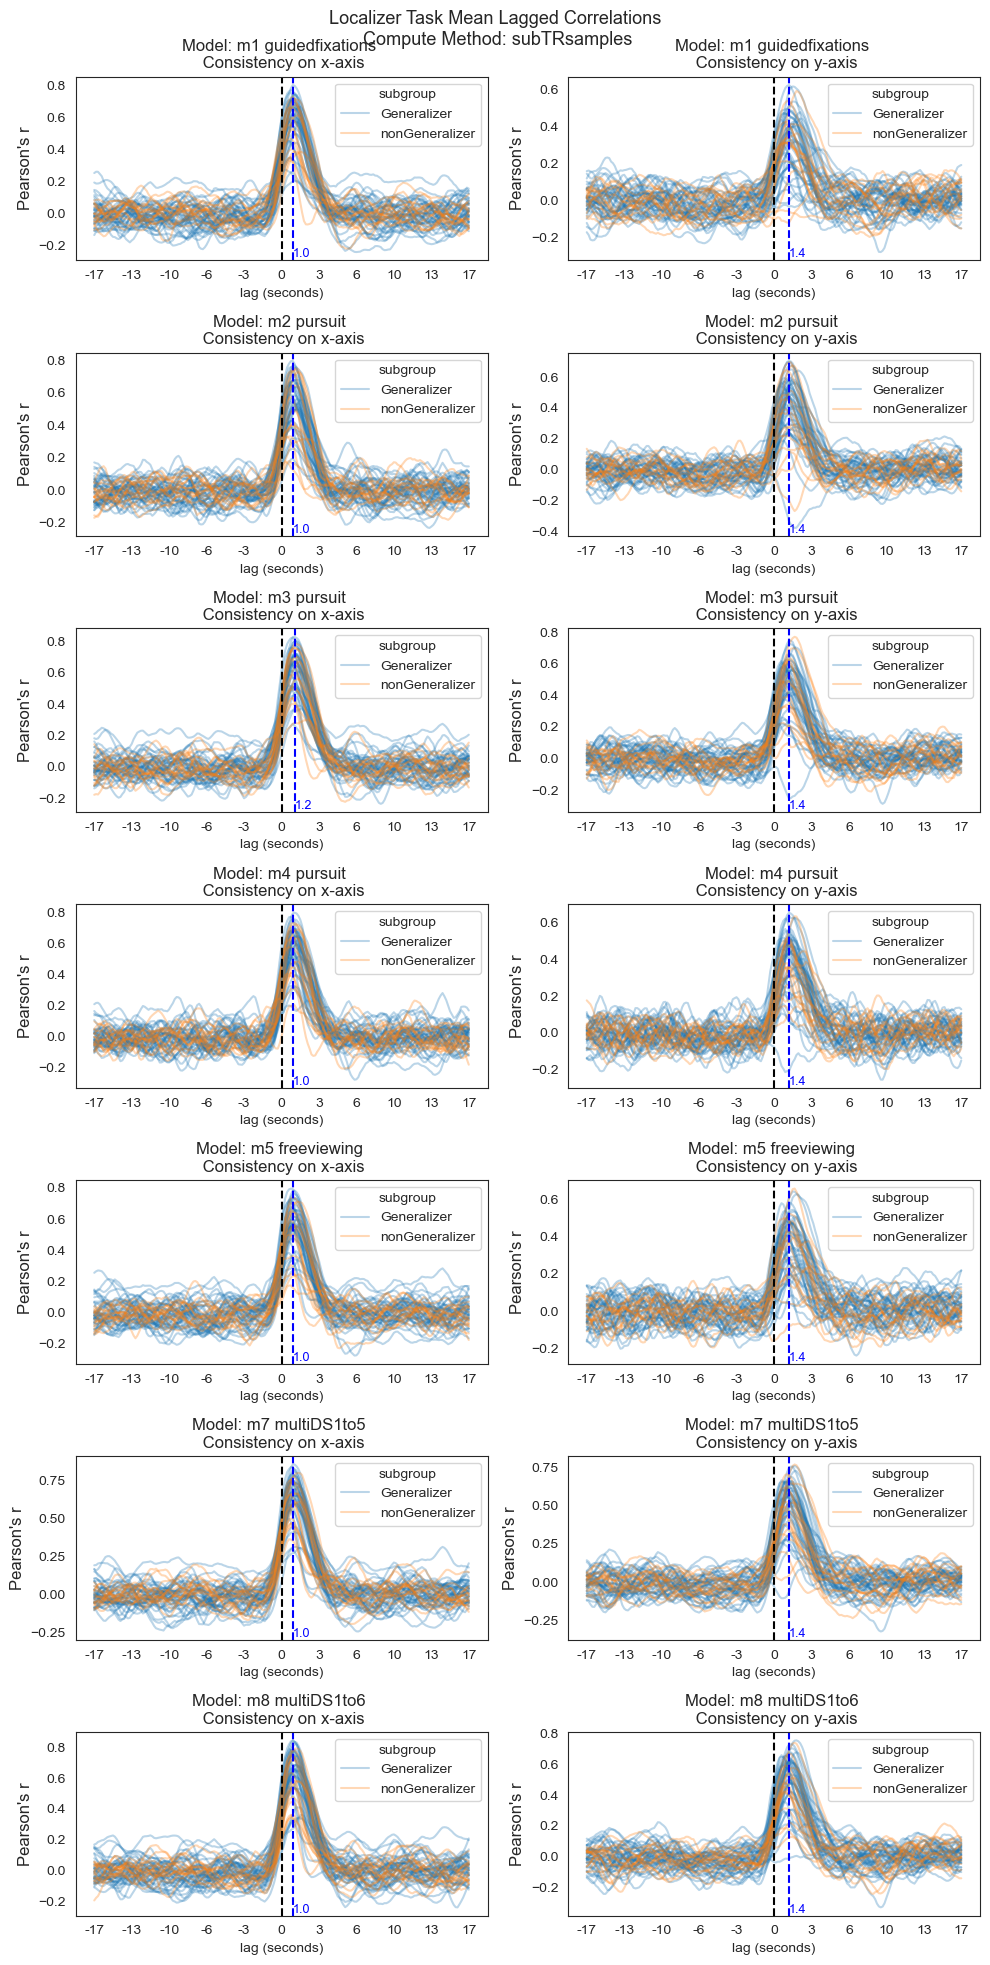

In [18]:
# plot mean correlation vs lag for each pretrained model, for x and y separately
for compute_method in lag_correlation_df["compute_method"].unique():
    figdf = lag_correlation_df[lag_correlation_df["compute_method"]==compute_method].copy()
    if compute_method == "median":
        xlabel="lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)
    elif compute_method == "subTRsamples":
        xlabel="lag (seconds)"
        xvar = "lag_sec"
        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)
    xticklabels = [str(int(x)) for x in xticks]
    fig, axes = plt.subplots(figdf.pretrainedmodel.nunique(),2, figsize=(10,20))
    for k, mname in enumerate(figdf.pretrainedmodel.unique()):
        axdf = figdf[figdf.pretrainedmodel == mname].copy()
        for j,correlation_type in enumerate(['correlation_x','correlation_y']):
            ax = axes[k,j]
            sns.lineplot(data=axdf, x=xvar, y=correlation_type, hue="subgroup",units="subid", estimator=None,ax=ax, alpha=0.3)
            ax.axvline(x=0, color='black', linestyle='--')
            ax.set_title(f"Model: {mname.replace('_',' ')} \n Consistency on {correlation_type[-1]}-axis")
            ax.set_xlabel(xlabel)
            ax.set_ylabel("Pearson's r",fontsize=12)
            ax.set_xticks(xticks,labels=xticklabels)
            
            mean_corrs = axdf.groupby(xvar)[correlation_type].mean().values
            lags = axdf.groupby(xvar)[xvar].mean().values
            max_corr_idx = np.argmax(mean_corrs)
            max_corr_lag = lags[max_corr_idx]
            # mark the maximum correlation points using vertical lines
            ax.axvline(x=max_corr_lag, linestyle='--', color='blue')
            # add a text at the bottom of x-axis at the max_corr_lag position
            ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.1f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                    ha='left', va='bottom', fontsize=9, color='blue')
    fig.suptitle(f"Localizer Task Mean Lagged Correlations\n Compute Method: {compute_method}", fontsize=13)
    fig.tight_layout()

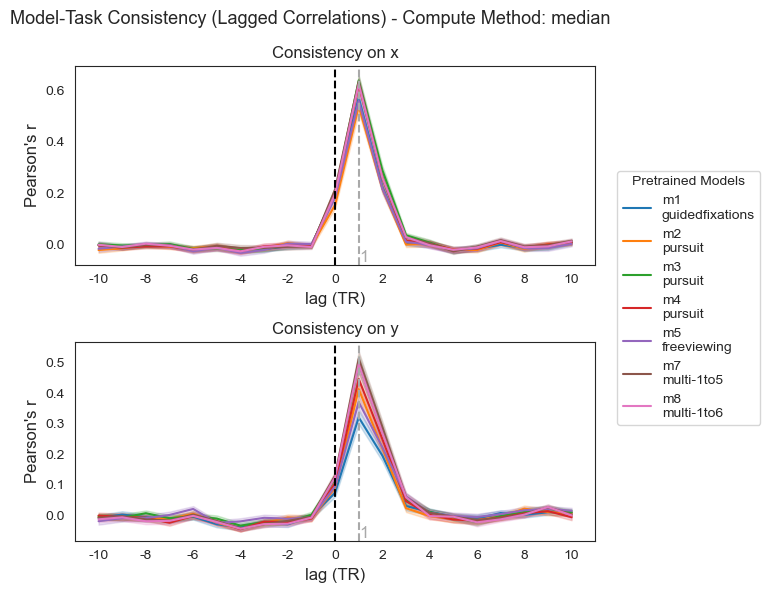

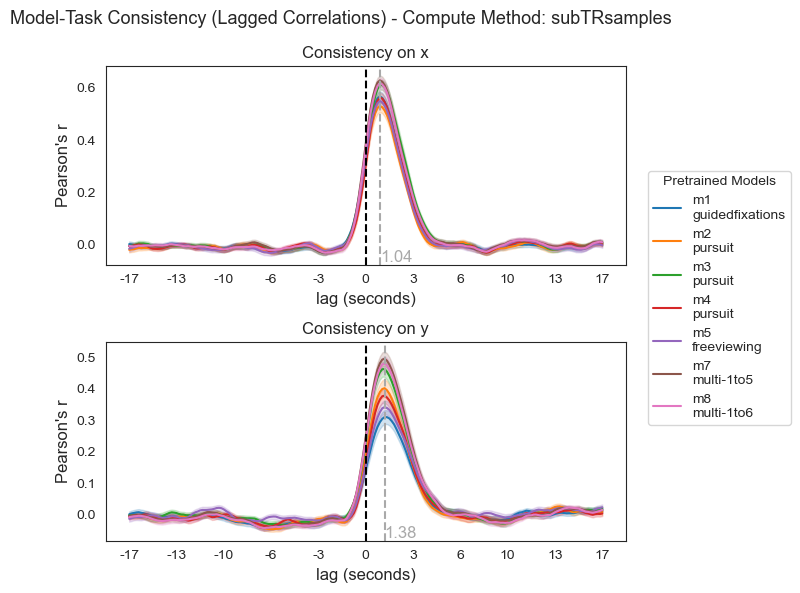

In [17]:
# plot mean correlation vs lag for each pretrained model, for x and y separately
for compute_method in lag_correlation_df["compute_method"].unique():
    figdf = lag_correlation_df[lag_correlation_df["compute_method"]==compute_method].copy()
    if compute_method == "median":
        xlabel="lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)
    elif compute_method == "subTRsamples":
        xlabel="lag (seconds)"
        xvar = "lag_sec"
        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)
    xticklabels = [str(int(x)) for x in xticks]
    fig, axes = plt.subplots(2,1, figsize=(6,6))
    for j,correlation_type in enumerate(['correlation_x','correlation_y']):
        ax = axes[j]
        sns.lineplot(data=figdf, x=xvar, y=correlation_type, hue="pretrainedmodel_print", errorbar="se",ax=ax, alpha=1)
        ax.axvline(x=0, color='black', linestyle='--')
        ax.set_title(f"Consistency on {correlation_type[-1]}")
        ax.set_xlabel(xlabel,fontsize=12)
        ax.set_ylabel("Pearson's r", fontsize=12)
        ax.set_xticks(xticks,labels=xticklabels)
        
        mean_corrs = figdf.groupby(xvar)[correlation_type].mean().values
        lags = figdf.groupby(xvar)[xvar].mean().values
        max_corr_idx = np.argmax(mean_corrs)
        max_corr_lag = lags[max_corr_idx]
        # mark the maximum correlation points using vertical lines
        ax.axvline(x=max_corr_lag, linestyle='--', color='darkgrey')
        # add a text at the bottom of x-axis at the max_corr_lag position
        ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.2f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                ha='left', va='bottom', fontsize=12, color='darkgrey')
    hdls, labs = axes[-1].get_legend_handles_labels()
    fig.legend(handles=hdls, labels=labs, loc='center left',title="Pretrained Models", bbox_to_anchor=(1,0.5))
    for ax in axes:
        ax.legend_.remove() 
    fig.suptitle(f"Model-Task Consistency (Lagged Correlations) - Compute Method: {compute_method}", fontsize=13) #
    fig.tight_layout()


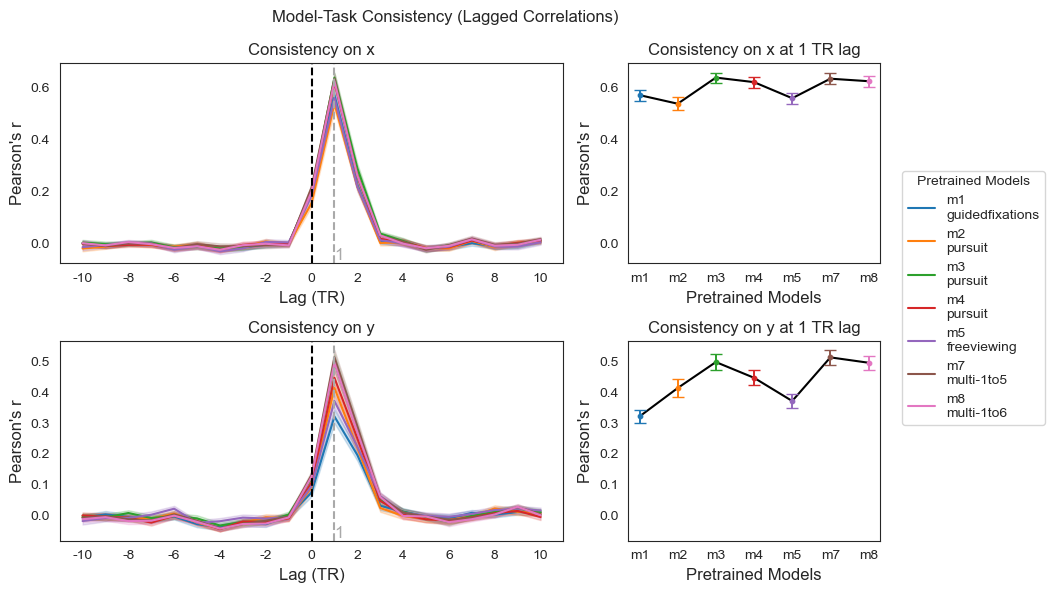

In [19]:
# plot mean correlation vs lag for each pretrained model, for x and y separately, only for TR
# pick the palette for models 
model_pal = dict(zip(
    figdf.pretrainedmodel_print.unique(),
    sns.color_palette(None, figdf.pretrainedmodel_print.nunique())
))
for compute_method in ["median"]:
    figdf = lag_correlation_df[lag_correlation_df["compute_method"]==compute_method].copy()
    
    if compute_method == "median":
        xlabel="Lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)
    elif compute_method == "subTRsamples":
        xlabel="Lag (seconds)"
        xvar = "lag_sec"
        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)
    xticklabels = [str(int(x)) for x in xticks]
    fig, axes = plt.subplots(2,2, figsize=(9,6),width_ratios=[1,0.5])
    for j,correlation_type in enumerate(['correlation_x','correlation_y']):
        ax = axes[j,0]
        sns.lineplot(data=figdf, x=xvar, y=correlation_type, hue="pretrainedmodel_print", palette=model_pal,errorbar="se",ax=ax, alpha=1)
        ax.axvline(x=0, color='black', linestyle='--')
        ax.set_title(f"Consistency on {correlation_type[-1]}")
        ax.set_xlabel(xlabel,fontsize=12)
        ax.set_xticks(xticks,labels=xticklabels)
        
        mean_corrs = figdf.groupby(xvar)[correlation_type].mean().values
        lags = figdf.groupby(xvar)[xvar].mean().values
        max_corr_idx = np.argmax(mean_corrs)
        max_corr_lag = lags[max_corr_idx]
        # mark the maximum correlation points using vertical lines
        ax.axvline(x=max_corr_lag, linestyle='--', color='darkgrey')
        # add a text at the bottom of x-axis at the max_corr_lag position
        ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.2f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                ha='left', va='bottom', fontsize=12, color='darkgrey')
        

        # plot the result at 1TR lag on the right side
        ax2 = axes[j,1]
        one_tr_lag = 1 
        tr1_df = figdf[figdf[xvar]==one_tr_lag].copy()
        tr1_df["pretrainedmodelshortname"] = tr1_df["pretrainedmodel_print"].str.slice(0,2)#only keep first two characters
        
        # compute the  summary statistics at 1 TR lag
        tr1_sum_df = tr1_df.groupby(["pretrainedmodel_print","pretrainedmodelshortname"])[correlation_type].agg(["mean", "sem"]).reset_index()
        ax2.plot(tr1_sum_df["pretrainedmodelshortname"], tr1_sum_df["mean"], color="black", linewidth=1.5)

        for (_, row), c in zip(tr1_sum_df.iterrows(), model_pal.values()):
            ax2.errorbar(
                row["pretrainedmodelshortname"], row["mean"],
                yerr=row["sem"],
                fmt="none",
                ecolor=c,        # colored errorbar
                capsize=4,
                elinewidth=1.4
            )
            ax2.scatter(
                row["pretrainedmodelshortname"], row["mean"],
                color=c,
                s=10,
                zorder=3
            )
        # make ax2 y-limit same as ax y-limit
        ax2.set_ylim(ax.get_ylim())
        #sns.lineplot(data=tr1_df, x='pretrainedmodelshortname', y=correlation_type, ax=ax2,
        #              estimator=None,units="subid", color='grey',alpha=0.3,linewidth=0.6)
        #sns.stripplot(data=one_tr_df, x='pretrainedmodelshortname', y=correlation_type, hue='pretrainedmodel_print', ax=ax2,
        #              dodge=False, alpha=0.5, size=3)
        #sns.barplot(data=one_tr_df, x='pretrainedmodelshortname', y=correlation_type, hue='pretrainedmodel_print', ax=ax2,
        #            errorbar='se',fill=False)
        
        ax2.set_title(f"Consistency on {correlation_type[-1]} at 1 TR lag")
        ax2.set_xlabel("Pretrained Models", fontsize=12)
    hdls, labs = axes.flatten()[-2].get_legend_handles_labels()
    fig.legend(handles=hdls, labels=labs, loc='center left',title="Pretrained Models", bbox_to_anchor=(1,0.5))
    for ax in axes.flatten():
        ax.set_ylabel("Pearson's r", fontsize=12)        
        if ax.legend_ is not None:
            ax.legend_.remove() 
    fig.suptitle(f"Model-Task Consistency (Lagged Correlations)") #  - Compute Method: {compute_method}", fontsize=13
    fig.tight_layout()

In [51]:
ax2.collections

<Axes.ArtistList of 14 collections>

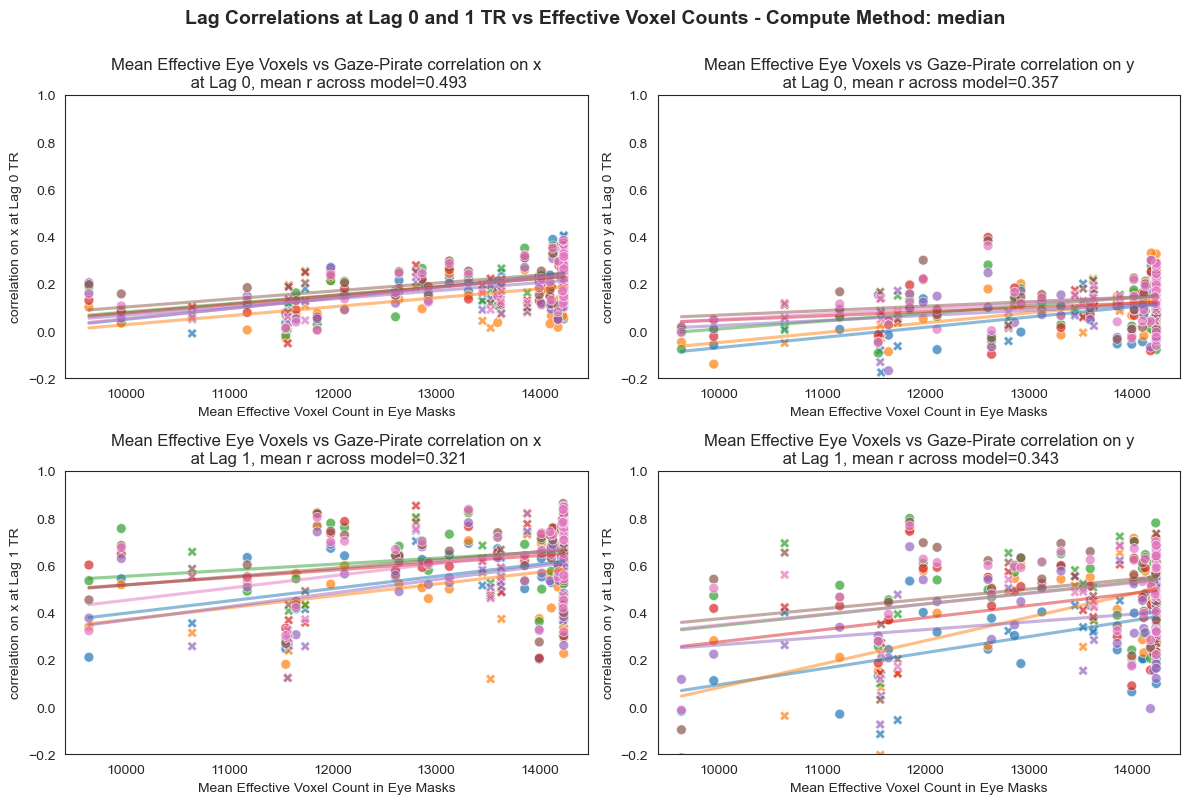

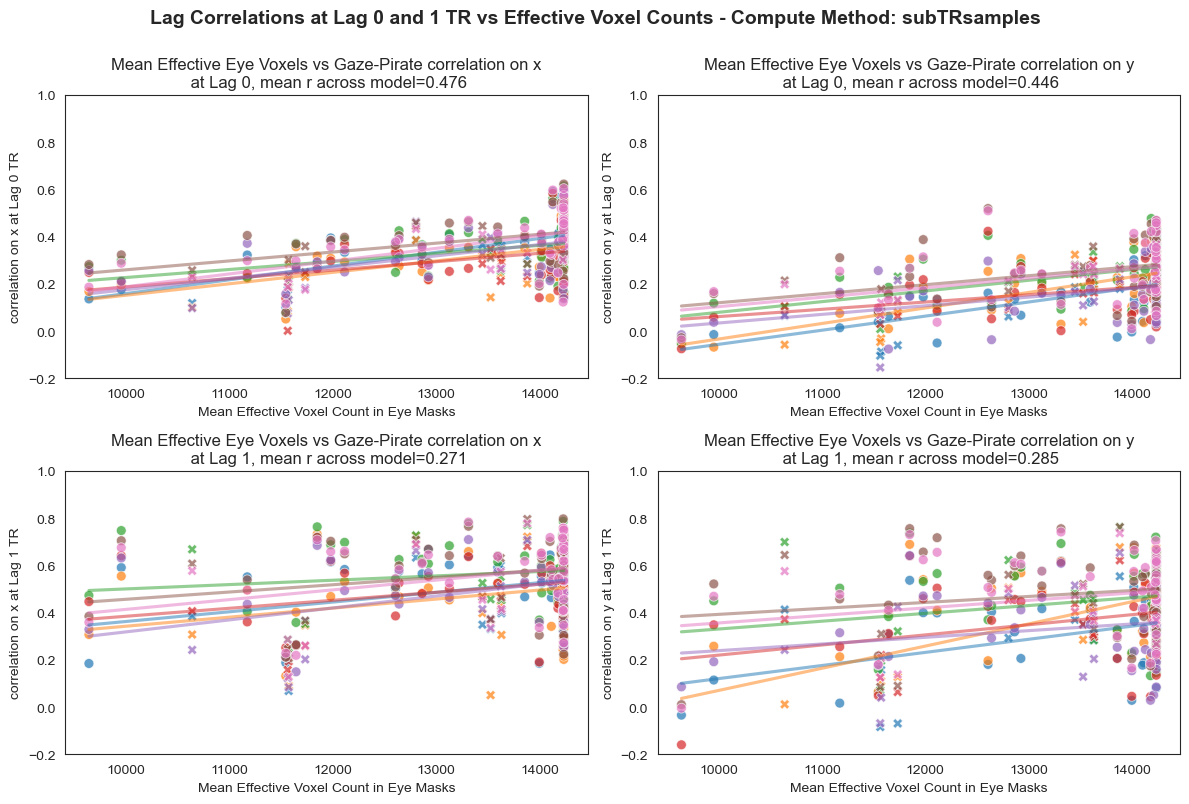

In [20]:
# consistency as a function of effective voxel counts
lag_correlation_effvox_df = lag_correlation_df.merge(
    mean_effvox_count_df[mean_effvox_count_df.taskname=="localizer"].copy(),
    on=['subid','taskname'], how='left')
lag_correlation_effvox_df["subgroup"] = ["Generalizers" if subid in generalizers else "nonGeneralizers" for subid in lag_correlation_effvox_df["subid"]]
# plot correlation at lag 0 and 1 vs mean effective voxel count for each pretrained model, for x and y separately
for compute_method in lag_correlation_effvox_df["compute_method"].unique():
    figdf = lag_correlation_effvox_df[lag_correlation_effvox_df["compute_method"]==compute_method].copy()
    
    fig, axes = plt.subplots(2,2, figsize=(12,8))
    for j,correlation_type in enumerate(['correlation_x','correlation_y']):
        for i, lag_TR in enumerate([0,1]):
            ax = axes[i,j]
            axdf = figdf[figdf["lag_TR"]==lag_TR].copy()
            sns.scatterplot(data=axdf, x='mean_effvox_count', y=correlation_type, hue='pretrainedmodel', style='subgroup', s=50, ax=ax, alpha=0.7)
            # plot regression line per pretrained model
            rs = []
            for model in axdf['pretrainedmodel'].unique():
                model_df = axdf[axdf['pretrainedmodel']==model].copy()
                sns.regplot(data=model_df, x='mean_effvox_count', y=correlation_type, scatter=False, ax=ax, ci=None, label=model, line_kws={'alpha':0.5})
                r, p = pearsonr(axdf['mean_effvox_count'], axdf[correlation_type])
                rs.append((model, r, p))
            # get the max r value and its corresponding p value
            # max_r_model, r, p = max(rs, key=lambda x: abs(x[1]))
            # get the mean r value across models
            r = np.mean([r for _, r, _ in rs])
            ax.set_title(f"Mean Effective Eye Voxels vs Gaze-Pirate {correlation_type.replace('_',' on ')}\n at Lag {lag_TR}, mean r across model={r:.3f}")
            ax.set_xlabel("Mean Effective Voxel Count in Eye Masks")
            ax.set_ylabel(f"{correlation_type.replace('_',' on ')} at Lag {lag_TR} TR")
            ax.legend_.remove()
            #ax.legend(title='Pretrained Model', loc='lower right')
            ax.set_ylim([-0.2,1.0])
    fig.suptitle(f"Lag Correlations at Lag 0 and 1 TR vs Effective Voxel Counts - Compute Method: {compute_method}", fontsize=14,fontweight='bold', y=1)
    fig.tight_layout()

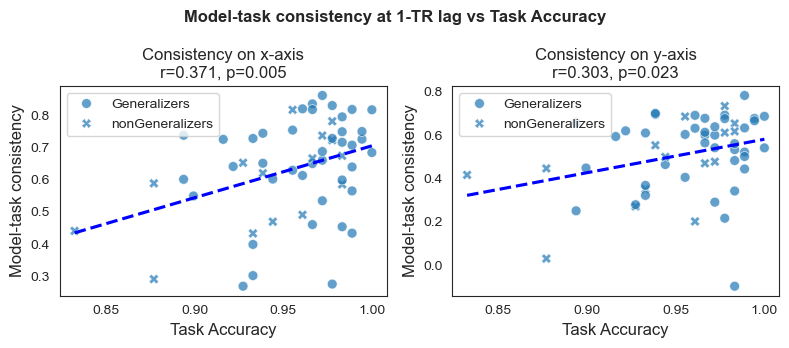

In [21]:
# consistency as a function of response accuracy

for compute_method in ["median"]:
    for mname in lag_correlation_effvox_df["pretrainedmodel"].unique()[-2:-1]:
        figdf = lag_correlation_effvox_df[
            (lag_correlation_effvox_df["compute_method"]==compute_method) &
            (lag_correlation_effvox_df["pretrainedmodel"]==mname)
        ].copy()
        fig, axes = plt.subplots(1,2, figsize=(8,3.5),squeeze=False)
        for j,correlation_type in enumerate(['correlation_x','correlation_y']):
            for i, lag_TR in enumerate([1]):
                ax = axes[i,j]
                #mean_corrs = figdf.groupby("lag_sec")[correlation_type].mean().values
                #lags = figdf.groupby("lag_sec")["lag_sec"].mean().values
                #max_corr_idx = np.argmax(mean_corrs)
                #max_corr_lag = lags[max_corr_idx]
                
                axdf = figdf[figdf["lag_TR"]==lag_TR].copy()
                sns.scatterplot(data=axdf, x='meanacc', y=correlation_type, style='subgroup', s=50, ax=ax, alpha=0.7)
                sns.regplot(data=axdf, x='meanacc', y=correlation_type, scatter=False, ax=ax, ci=None, color='blue', line_kws={'linestyle':'--'})
                # compute correlation between mean_effvox_count and correlation_type
                r, p = pearsonr(axdf['meanacc'], axdf[correlation_type])
                

                ax.set_title(f"Consistency on {correlation_type[-1]}-axis\nr={r:.3f}, p={p:.3f}")
                ax.set_xlabel("Task Accuracy",fontsize=12)
                ax.set_ylabel(f"Model-task consistency", fontsize=12)
                ax.legend(title="")
                
        fig.suptitle(f"Model-task consistency at 1-TR lag vs Task Accuracy - Model: {mname[:2]} - Compute Method: {compute_method}", fontsize=12,fontweight='bold')
        fig.suptitle(f"Model-task consistency at 1-TR lag vs Task Accuracy", fontsize=12,fontweight='bold')
        fig.tight_layout()

In [71]:
figdf

,lag_TR,lag_sec,correlation_x,correlation_y,subid,run,pretrainedmodel,taskname,max_corr_lag_x,max_corr_lag_y,compute_method,meanacc,meanrt,subgroup,pretrainedmodel_print,correlation_xymean
0,-10.0,-17.30,-0.106051,0.032922,sub001,1,m1_guidedfixations,localizer,1.0,1.0,median,0.938547,0.661600,Generalizer,m1\nguidedfixations,-0.036564
1,-9.0,-15.57,0.014898,0.003153,sub001,1,m1_guidedfixations,localizer,1.0,1.0,median,0.938547,0.661600,Generalizer,m1\nguidedfixations,0.009026
2,-8.0,-13.84,0.010497,-0.084671,sub001,1,m1_guidedfixations,localizer,1.0,1.0,median,0.938547,0.661600,Generalizer,m1\nguidedfixations,-0.037087
3,-7.0,-12.11,-0.060975,0.031738,sub001,1,m1_guidedfixations,localizer,1.0,1.0,median,0.938547,0.661600,Generalizer,m1\nguidedfixations,-0.014619
4,-6.0,-10.38,-0.016571,-0.022886,sub001,1,m1_guidedfixations,localizer,1.0,1.0,median,0.938547,0.661600,Generalizer,m1\nguidedfixations,-0.019729
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86818,6.0,10.38,-0.113423,0.082752,sub130,1,m8_multiDS1to6,localizer,1.0,1.0,median,0.988827,0.708329,Generalizer,m8\nmulti-1to6,-0.015335
86819,7.0,12.11,0.086106,0.031067,sub130,1,m8_multiDS1to6,localizer,1.0,1.0,median,0.988827,0.708329,Generalizer,m8\nmulti-1to6,0.058586
86820,8.0,13.84,0.104675,-0.069707,sub130,1,m8_multiDS1to6,localizer,1.0,1.0,median,0.988827,0.708329,Generalizer,m8\nmulti-1to6,0.017484
86821,9.0,15.57,0.092999,-0.036633,sub130,1,m8_multiDS1to6,localizer,1.0,1.0,median,0.988827,0.708329,Generalizer,m8\nmulti-1to6,0.028183


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


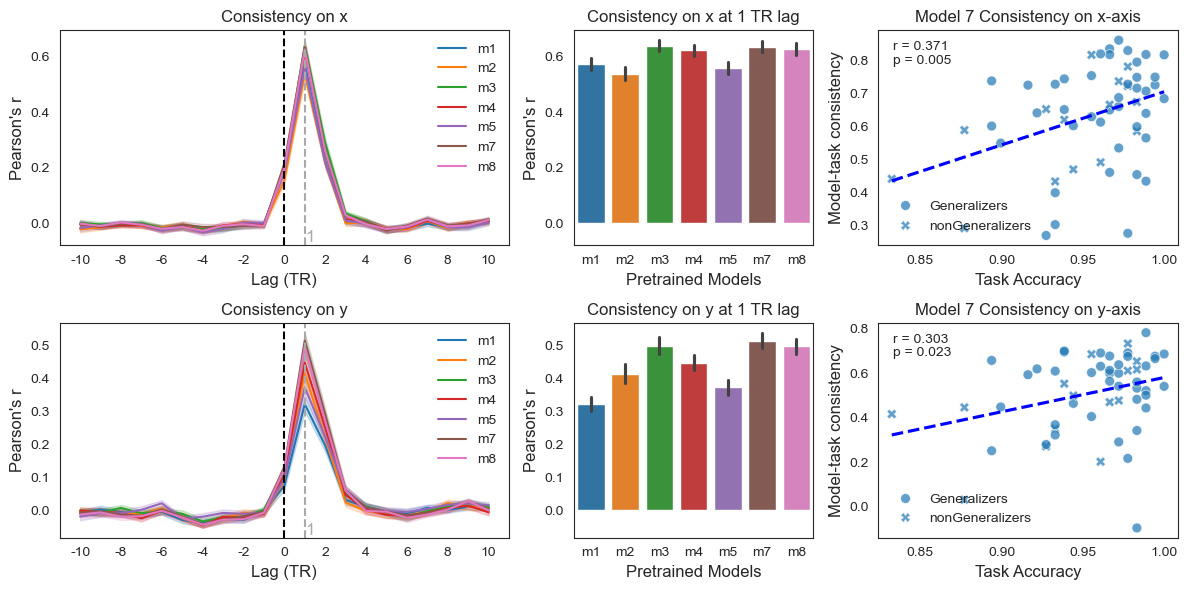

In [23]:
# plot the lag correlation, mean consistency and the correlation plot in the same figure
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(12,2*3))
gs = GridSpec(2, 3, width_ratios=[1.5,0.8,1], height_ratios=[1,1])
axes = [[fig.add_subplot(gs[0,0]), fig.add_subplot(gs[0,1])],
        [fig.add_subplot(gs[1,0]), fig.add_subplot(gs[1,1])],
        [fig.add_subplot(gs[0,2]), fig.add_subplot(gs[1,2])]]

# in the first two cols:
# plot mean correlation vs lag for each pretrained model, for x and y separately, only for TR
# pick the palette for models 
compute_method = "median"
figdf = lag_correlation_df[lag_correlation_df["compute_method"]==compute_method].copy()
figdf["pretrainedmodelshortname"] = figdf["pretrainedmodel_print"].str.slice(0,2)#only keep first two characters
    
model_pal = dict(zip(
    figdf.pretrainedmodelshortname.unique(),
    sns.color_palette(None, figdf.pretrainedmodelshortname.nunique())
))

if compute_method == "median":
    xlabel="Lag (TR)"
    xvar = "lag_TR"
    xticks = np.arange(-10,11,2)
elif compute_method == "subTRsamples":
    xlabel="Lag (seconds)"
    xvar = "lag_sec"
    min_lag_s = figdf[xvar].min()
    max_lag_s = figdf[xvar].max()
    delta  = (max_lag_s - min_lag_s)/10
    xticks = np.arange(min_lag_s, max_lag_s+1, delta)
xticklabels = [str(int(x)) for x in xticks]
for j,correlation_type in enumerate(['correlation_x','correlation_y']):
    ax = axes[j][0]
    sns.lineplot(data=figdf, x=xvar, y=correlation_type, hue="pretrainedmodelshortname", palette=model_pal,errorbar="se",ax=ax, alpha=1)
    ax.axvline(x=0, color='black', linestyle='--')
    ax.set_title(f"Consistency on {correlation_type[-1]}")
    ax.set_xlabel(xlabel,fontsize=12)
    ax.set_xticks(xticks,labels=xticklabels)
    
    mean_corrs = figdf.groupby(xvar)[correlation_type].mean().values
    lags = figdf.groupby(xvar)[xvar].mean().values
    max_corr_idx = np.argmax(mean_corrs)
    max_corr_lag = lags[max_corr_idx]
    # mark the maximum correlation points using vertical lines
    ax.axvline(x=max_corr_lag, linestyle='--', color='darkgrey')
    # add a text at the bottom of x-axis at the max_corr_lag position
    ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.2f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
            ha='left', va='bottom', fontsize=12, color='darkgrey')
    

    # plot the result at 1TR lag on the right side
    ax2 = axes[j][1]
    one_tr_lag = 1 
    tr1_df = figdf[figdf[xvar]==one_tr_lag].copy()
    
    sns.barplot(data=tr1_df, 
                x='pretrainedmodelshortname', y=correlation_type,
                hue='pretrainedmodelshortname', 
                ax=ax2,
                errorbar='se')
    # make ax2 y-limit same as ax y-limit
    ax2.set_ylim(ax.get_ylim())
    
    ax2.set_title(f"Consistency on {correlation_type[-1]} at 1 TR lag")
    ax2.set_xlabel("Pretrained Models", fontsize=12)
    
#hdls, labs = axes[0][1].get_legend_handles_labels()
#fig.legend(handles=hdls, labels=labs, loc='center right',title="Pretrained Models", bbox_to_anchor=(0,0.5))
for ax in sum(axes, []):
    ax.set_ylabel("Pearson's r", fontsize=12)        
    ax.legend(title="",frameon=False)
    #if ax.legend_ is not None:
        #ax.legend_.remove() 

mname = "m7_multiDS1to5"
figdf = lag_correlation_effvox_df[
    (lag_correlation_effvox_df["compute_method"]==compute_method) &
    (lag_correlation_effvox_df["pretrainedmodel"]==mname)
].copy()
for j,correlation_type in enumerate(['correlation_x','correlation_y']):
    lag_TR = 1
    ax = axes[2][j]
    #mean_corrs = figdf.groupby("lag_sec")[correlation_type].mean().values
    #lags = figdf.groupby("lag_sec")["lag_sec"].mean().values
    #max_corr_idx = np.argmax(mean_corrs)
    #max_corr_lag = lags[max_corr_idx]
    
    axdf = figdf[figdf["lag_TR"]==lag_TR].copy()
    sns.scatterplot(data=axdf, x='meanacc', y=correlation_type, style='subgroup', s=50, ax=ax, alpha=0.7)
    sns.regplot(data=axdf, x='meanacc', y=correlation_type, scatter=False, ax=ax, ci=None, color='blue', line_kws={'linestyle':'--'})
    # compute correlation between mean_effvox_count and correlation_type
    r, p = pearsonr(axdf['meanacc'], axdf[correlation_type])
    ax.text(0.05,0.95,
        f"r = {r:.3f}\np = {p:.3f}",
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment='top'
    )

    ax.set_title(f"Model 7 Consistency on {correlation_type[-1]}-axis")
    ax.set_xlabel("Task Accuracy",fontsize=12)
    ax.set_ylabel(f"Model-task consistency", fontsize=12)
    ax.legend(title="", loc='lower left',frameon=False,
              framealpha=0)
    #ax.legend().remove()
    #fig.suptitle(f"Model-Task Consistency (Lagged Correlations)") #  - Compute Method: {compute_method}", fontsize=13
fig.tight_layout()
fig.savefig(os.path.join(ROIRSAdir,"finalfigs","figS7a-c.tif"),dpi=300,bbox_inches="tight")    


In [56]:
lag_correlation_effvox_df["pretrainedmodel"].unique()

array(['m1_guidedfixations', 'm2_pursuit', 'm3_pursuit', 'm4_pursuit',
       'm5_freeviewing', 'm7_multiDS1to5', 'm8_multiDS1to6'], dtype=object)

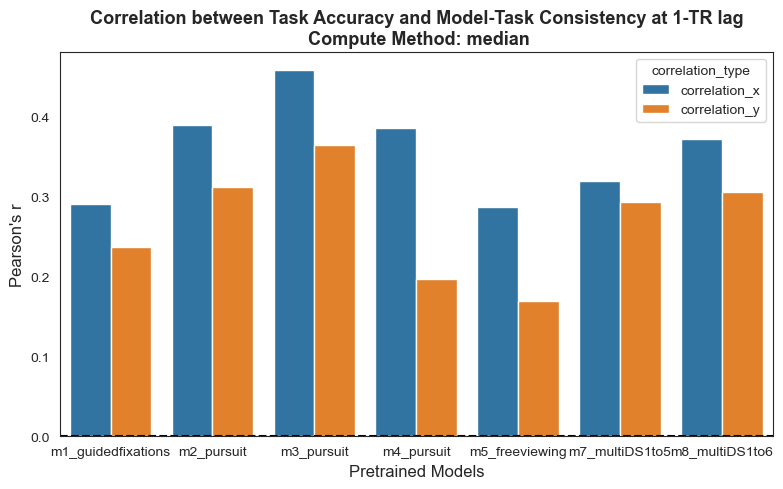

In [142]:
import scipy.stats
# plot the model-task consistency at 1-TR lag vs task accuracy correlation coefficient for each pretrained model, for x and y separately, all in one figure
# compute the correlation for each model
for compute_method in ["median"]:
    corr_acc_consistency_dfs = []
    for mname in lag_correlation_effvox_df["pretrainedmodel"].unique():
        figdf = lag_correlation_effvox_df[
            (lag_correlation_effvox_df["compute_method"]==compute_method) &
            (lag_correlation_effvox_df["pretrainedmodel"]==mname) &
            (lag_correlation_effvox_df["lag_TR"]==1)
        ].copy()
        for correlation_type in ['correlation_x','correlation_y']:
            r, p = scipy.stats.spearmanr(figdf['meanacc'], figdf[correlation_type])
            tmpdf = pd.DataFrame({
                "pretrainedmodel": [mname],
                "correlation_type": [correlation_type],
                "r": [r],
                "p": [p]
            })
            corr_acc_consistency_dfs.append(tmpdf)
    corr_acc_consistency_df = pd.concat(corr_acc_consistency_dfs, axis=0).reset_index(drop=True)
    
    # plot the correlation coefficients
    fig, ax = plt.subplots(figsize=(8,5))
    sns.barplot(data=corr_acc_consistency_df, x='pretrainedmodel', y='r', hue='correlation_type', ax=ax)
    ax.set_title(f"Correlation between Task Accuracy and Model-Task Consistency at 1-TR lag\n Compute Method: {compute_method}", fontsize=13,fontweight='bold')
    ax.set_xlabel("Pretrained Models", fontsize=12)
    ax.set_ylabel("Pearson's r", fontsize=12)
    ax.axhline(y=0, color='black', linestyle='--')
    plt.tight_layout()


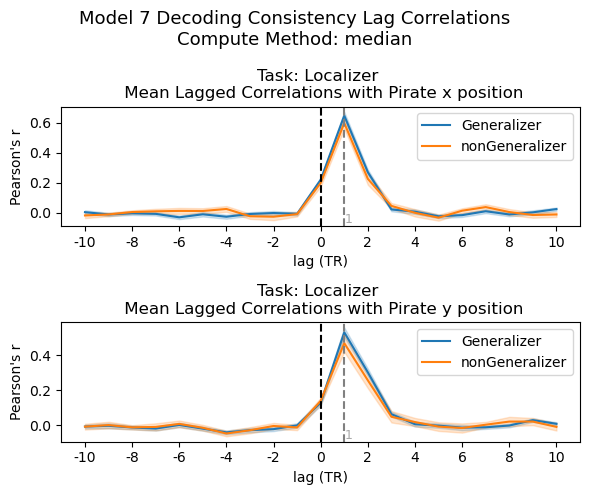

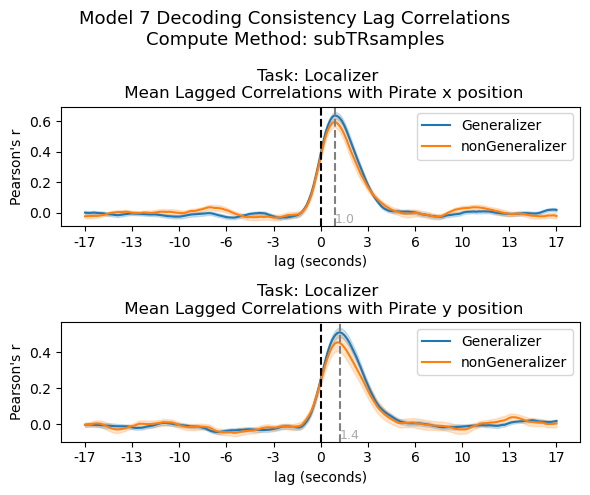

In [54]:
# only plot for m7_multiDS1to5 for Generalizers vs nonGeneralizers, see that there is no big difference
for compute_method in lag_correlation_df["compute_method"].unique():
    figdf = lag_correlation_df[(lag_correlation_df["compute_method"]==compute_method) & (lag_correlation_df["pretrainedmodel"]=="m7_multiDS1to5")].copy()
    if compute_method == "median":
        xlabel="lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)
    elif compute_method == "subTRsamples":
        xlabel="lag (seconds)"
        xvar = "lag_sec"
        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)
    xticklabels = [str(int(x)) for x in xticks]
    fig, axes = plt.subplots(2,1, figsize=(6,5))
    for j,correlation_type in enumerate(['correlation_x','correlation_y']):
        ax = axes[j]
        sns.lineplot(data=figdf, x=xvar, y=correlation_type, hue="subgroup", errorbar="se",ax=ax, alpha=1)
        ax.legend(title="")
        ax.axvline(x=0, color='black', linestyle='--')
        ax.set_title(f"Task: Localizer \n Mean Lagged Correlations with Pirate {correlation_type[-1]} position")
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Pearson's r")
        ax.set_xticks(xticks,labels=xticklabels)
        
        mean_corrs = figdf.groupby(xvar)[correlation_type].mean().values
        lags = figdf.groupby(xvar)[xvar].mean().values
        max_corr_idx = np.argmax(mean_corrs)
        max_corr_lag = lags[max_corr_idx]
        # mark the maximum correlation points using vertical lines
        ax.axvline(x=max_corr_lag, linestyle='--', color='grey')
        # add a text at the bottom of x-axis at the max_corr_lag position
        ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.1f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                ha='left', va='bottom', fontsize=9, color='darkgrey')
    fig.suptitle(f"Model 7 Decoding Consistency Lag Correlations\nCompute Method: {compute_method}", fontsize=13)
    fig.tight_layout()

In [17]:
# # see if best lag correlates to task rt
# best_lag_dfs = []
# for mname in lag_correlation_df["pretrainedmodel"].unique():
#     for subid in subid_list:
#         subdf = lag_correlation_df[
#             (lag_correlation_df["pretrainedmodel"]==mname) &
#             (lag_correlation_df["subid"]==subid)&
#             (lag_correlation_df["compute_method"]=="subTRsamples")
#         ].copy()
#         for coord in ['x','y']:
#             max_lag_col = f"max_corr_lag_{coord}"
#             assert subdf[max_lag_col].nunique() == 1, "There should be only one max_corr_lag per subject per model per coord"
#             max_corr_lag = subdf[max_lag_col].unique()[0]
#             best_lag_row = subdf[(subdf["lag_sec"]-max_corr_lag).abs()<1e-6].copy()
#             assert best_lag_row.shape[0] == 1, "There should be only one row for the best lag, but got %d"%best_lag_row.shape[0]
#             best_lag_dfs.append(best_lag_row)

# best_lag_df = pd.concat(best_lag_dfs).reset_index(drop=True)
# best_lag_df["subgroup"] = ["Generalizers" if subid in generalizers else "nonGeneralizers" for subid in best_lag_df["subid"]]

# # for each pretrained model, plot best lag vs mean RT
# for mname in best_lag_df["pretrainedmodel"].unique():
#     figdf = best_lag_df[best_lag_df["pretrainedmodel"]==mname].copy()
#     fig, axes = plt.subplots(1,3, figsize=(12,3.5))
#     for j,coord in enumerate(['x','y']):
#         ax = axes[j]
#         corr_col = f"correlation_{coord}"
#         sns.scatterplot(data=figdf, x='meanrt', y=f'max_corr_lag_{coord}', style='subgroup', s=50, ax=ax, alpha=0.7)
#         sns.regplot(data=figdf, x='meanrt', y=f'max_corr_lag_{coord}', scatter=False, ax=ax, ci=None, color='black', line_kws={'linestyle':'--'})
#         # compute correlation between meanRT and lag_TR
#         r, p = pearsonr(figdf['meanrt'], figdf[f'max_corr_lag_{coord}'])
#         ax.set_title(f"Mean Task RT vs Best Lag TR for {coord.upper()} Coordinate\nr={r:.2f}, p={p:.3f}")
#         ax.set_xlabel("Mean Task Reaction Time (s)")
#         ax.set_ylabel("Best Lag (s)")
#         ax.legend_.remove()
#     # plot max of lag_x and lag_y vs meanRT
#     ax = axes[2]
#     mean_lag_xy = figdf[[f'max_corr_lag_x', f'max_corr_lag_y']].max(axis=1)
#     sns.scatterplot(data=figdf, x='meanrt', y=mean_lag_xy, style='subgroup', s=50, ax=ax, alpha=0.7)
#     sns.regplot(data=figdf, x='meanrt', y=mean_lag_xy, scatter=False, ax=ax, ci=None, color='black', line_kws={'linestyle':'--'})
#     r,p = pearsonr(figdf["meanrt"],mean_lag_xy)
#     ax.set_title(f"Mean Task RT vs Best Lag TR (max of X and Y)\nr={r:.2f}, p={p:.3f}")
#     fig.suptitle(f"Best Lag vs Task RT - Model: {mname}", fontsize=13, y=1)
#     fig.tight_layout()